# Chapter 11: Novelty and Outlier Detection

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup  
**Publisher:** Packt Publishing

## Learning Objectives

1. Understand the difference between outlier detection and novelty detection.
2. Implement Isolation Forest.
3. Apply One-Class SVM for novelty detection.
4. Detect outliers using Local Outlier Factor (LOF).
5. Evaluate outlier detection models.
6. Understand strategies for handling detected outliers.
7. Compare anomaly detection techniques.

## Chapter Contents

1. Introduction to Outlier and Novelty Detection
2. Understanding Isolation Forest
3. One-Class SVM for Novelty Detection
4. Detecting Outliers with LOF
5. Evaluating Outlier Detection Models
6. Handling Detected Outliers
7. Choosing the Right Detection Technique
8. Practical Exercises
9. Summary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Introduction to Outlier and Novelty Detection

Real-world datasets can contain unusual observations that differ
substantially from the majority of the data.

Two related concepts are:

### Outlier Detection

Outlier detection identifies observations that deviate from the
general pattern of the dataset being analyzed.

### Novelty Detection

Novelty detection identifies observations that are unusual compared
with a reference dataset considered normal. The reference data is
typically used to fit the model, and new observations are evaluated
later.

### Applications

- Fraud detection in financial transactions.
- Industrial equipment monitoring.
- Network intrusion detection.
- Medical anomaly screening.
- Identifying unusual sensor readings.

Outlier and novelty detection are important because unusual data
may indicate errors, rare events, operational problems, or malicious
activity. However, an unusual observation is not automatically an error.

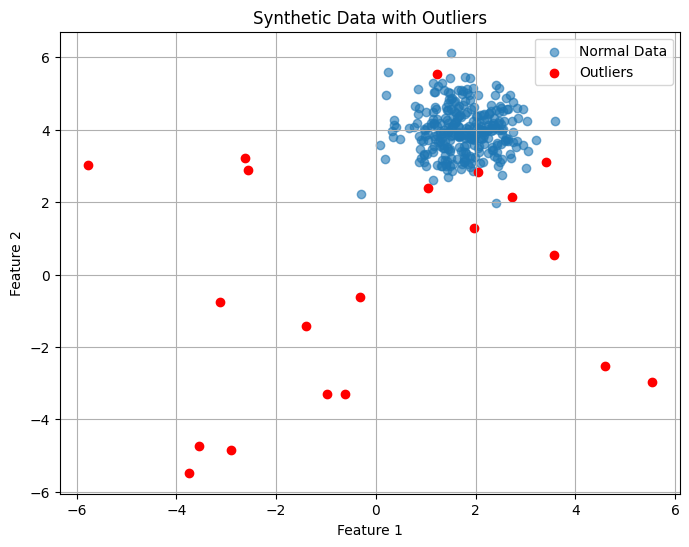

In [2]:
# Generate normal observations
X, _ = make_blobs(
    n_samples=300,
    centers=1,
    cluster_std=0.60,
    random_state=2024
)

# Generate outliers
np.random.seed(2024)

outliers = np.random.uniform(
    low=-6,
    high=6,
    size=(20, 2)
)

X_with_outliers = np.vstack([X, outliers])

# Visualize the dataset
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    label="Normal Data",
    alpha=0.6
)

plt.scatter(
    outliers[:, 0],
    outliers[:, 1],
    color="red",
    label="Outliers"
)

plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How It Works

The `make_blobs()` function generates 300 observations around one
cluster center. The relatively small cluster standard deviation
creates a concentrated group of normal observations.

The code then generates 20 additional points using a uniform
distribution and combines them with the original observations.

The scatter plot displays the original cluster and the added points
in different colors. Points far from the main concentration are
potential outliers.

Because this is synthetic data, the added outliers are known.
In real datasets, the observations that should be considered anomalous
are usually unknown and must be estimated by a detection algorithm.

## 2. Understanding Isolation Forest

Isolation Forest is an anomaly detection algorithm that identifies
observations that are easier to isolate from the rest of the data.

The method builds an ensemble of randomized trees. During tree
construction, features and split values are selected to partition
the observations.

Unusual observations often require fewer splits to isolate than
observations located in dense regions.

### Important Parameters

- `n_estimators`: Number of trees in the ensemble.
- `contamination`: Expected proportion of outliers, used to set
  the decision threshold.
- `max_samples`: Number of samples used to build each tree.
- `random_state`: Controls reproducibility.

Isolation Forest is useful for detecting anomalies in datasets
where normal observations form the dominant pattern. Its results
depend on the data and parameter settings.

In [3]:
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.06,
    random_state=2024
)

isolation_labels = isolation_forest.fit_predict(X_with_outliers)

# In scikit-learn, -1 means outlier and 1 means inlier
n_detected_outliers = np.sum(isolation_labels == -1)
n_detected_inliers = np.sum(isolation_labels == 1)

print("Detected outliers:", n_detected_outliers)
print("Detected inliers:", n_detected_inliers)

Detected outliers: 20
Detected inliers: 300


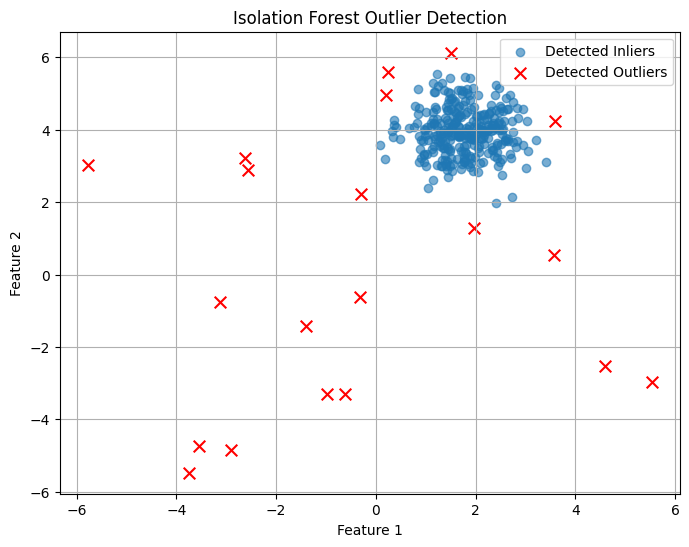

In [4]:
plt.figure(figsize=(8, 6))

inlier_mask = isolation_labels == 1
outlier_mask = isolation_labels == -1

plt.scatter(
    X_with_outliers[inlier_mask, 0],
    X_with_outliers[inlier_mask, 1],
    label="Detected Inliers",
    alpha=0.6
)

plt.scatter(
    X_with_outliers[outlier_mask, 0],
    X_with_outliers[outlier_mask, 1],
    color="red",
    marker="x",
    s=70,
    label="Detected Outliers"
)

plt.title("Isolation Forest Outlier Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How It Works

The Isolation Forest model assigns each observation a prediction
label:

- `1`: The observation is considered an inlier.
- `-1`: The observation is considered an outlier.

The scatter plot distinguishes the observations classified by
the model.

The `contamination` parameter influences the expected proportion
of outliers and the decision threshold. It should be selected with
care because an unsuitable value can produce too many or too few
detections.

The model does not know the true identity of the added outliers.
Its predictions are estimates based on the structure of the data.

## 3. One-Class SVM for Novelty Detection

One-Class Support Vector Machine (One-Class SVM) learns a boundary
around the reference observations and identifies observations
outside that learned region as potential novelties.

It is useful when training data primarily represents normal behavior
and new observations need to be screened.

### Important Parameters

- `kernel`: Defines the similarity function used by the model.
- `nu`: An upper bound on the fraction of training errors and a
  lower bound on the fraction of support vectors.
- `gamma`: Controls the influence of individual samples for kernels
  such as RBF.

One-Class SVM can model nonlinear boundaries using an RBF kernel.
However, its performance depends on feature scaling and parameter
selection.

In [6]:
# Fit using the normal reference observations only
scaler = StandardScaler()

X_normal_scaled = scaler.fit_transform(X)
X_all_scaled = scaler.transform(X_with_outliers)

one_class_svm = OneClassSVM(
    kernel="rbf",
    nu=0.06,
    gamma="scale"
)

one_class_svm.fit(X_normal_scaled)

svm_labels = one_class_svm.predict(X_all_scaled)

print("Detected outliers:", np.sum(svm_labels == -1))
print("Detected inliers:", np.sum(svm_labels == 1))

Detected outliers: 44
Detected inliers: 276


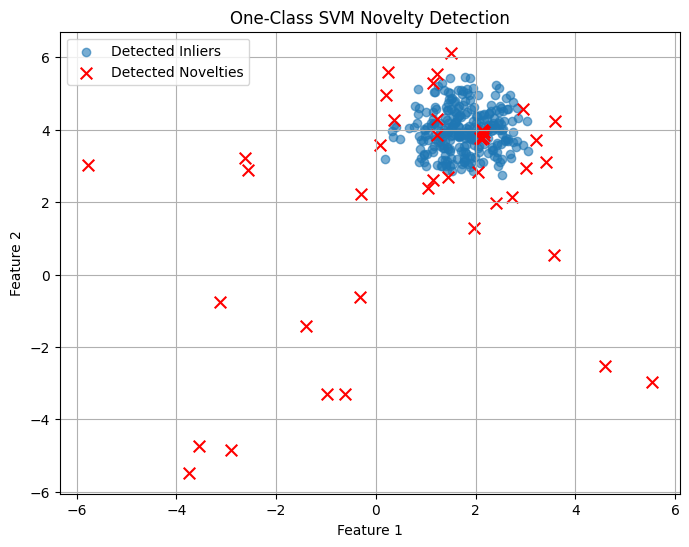

In [7]:
plt.figure(figsize=(8, 6))

svm_inlier_mask = svm_labels == 1
svm_outlier_mask = svm_labels == -1

plt.scatter(
    X_with_outliers[svm_inlier_mask, 0],
    X_with_outliers[svm_inlier_mask, 1],
    label="Detected Inliers",
    alpha=0.6
)

plt.scatter(
    X_with_outliers[svm_outlier_mask, 0],
    X_with_outliers[svm_outlier_mask, 1],
    color="red",
    marker="x",
    s=70,
    label="Detected Novelties"
)

plt.title("One-Class SVM Novelty Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How It Works

The model is trained using the normal observations as a reference
dataset. The added observations are then evaluated against the
learned boundary.

Feature scaling is important for SVM because feature magnitudes
can affect distances and kernel calculations.

The `nu` parameter influences the learned boundary and the expected
fraction of training observations treated as outliers.

The predictions should be interpreted as potential novelties rather
than definitive proof that an observation is invalid or dangerous.

## 4. Detecting Outliers with Local Outlier Factor (LOF)

Local Outlier Factor (LOF) detects anomalies by comparing the local
density around an observation with the local densities of its neighbors.

An observation may be considered an outlier if its local density is
substantially lower than the densities around nearby observations.

### Important Parameters

- `n_neighbors`: Number of neighboring observations used to estimate
  local density.
- `contamination`: Expected proportion of outliers, used to set the
  decision threshold.
- `novelty`: Determines whether the model is configured for novelty
  detection on new observations.

LOF is useful when anomalies occur in regions where density varies
across the dataset. Its results depend on the neighborhood size and
the structure of the data.

In [8]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.06
)

lof_labels = lof.fit_predict(X_with_outliers)

print("Detected outliers:", np.sum(lof_labels == -1))
print("Detected inliers:", np.sum(lof_labels == 1))

Detected outliers: 20
Detected inliers: 300


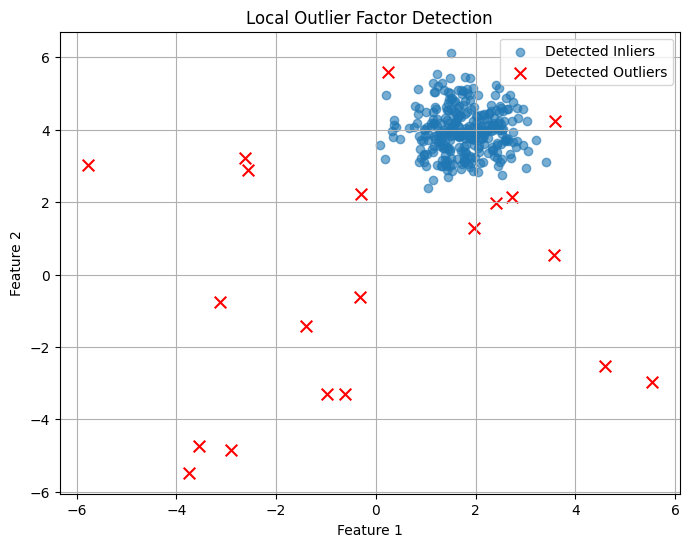

In [9]:
plt.figure(figsize=(8, 6))

lof_inlier_mask = lof_labels == 1
lof_outlier_mask = lof_labels == -1

plt.scatter(
    X_with_outliers[lof_inlier_mask, 0],
    X_with_outliers[lof_inlier_mask, 1],
    label="Detected Inliers",
    alpha=0.6
)

plt.scatter(
    X_with_outliers[lof_outlier_mask, 0],
    X_with_outliers[lof_outlier_mask, 1],
    color="red",
    marker="x",
    s=70,
    label="Detected Outliers"
)

plt.title("Local Outlier Factor Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Novelty mode allows prediction on new observations
lof_novelty = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.06,
    novelty=True
)

lof_novelty.fit(X_normal_scaled)

lof_novelty_labels = lof_novelty.predict(X_all_scaled)

print("Detected novelties:", np.sum(lof_novelty_labels == -1))
print("Detected normal observations:", np.sum(lof_novelty_labels == 1))

Detected novelties: 36
Detected normal observations: 284


### How It Works

In its standard mode, LocalOutlierFactor estimates local outlier
scores for the observations supplied to `fit_predict()`.

With `novelty=True`, the model can be fitted on a reference dataset
and then used to evaluate new observations with `predict()`.

The two modes serve different purposes and should not be confused.

LOF compares local densities rather than relying solely on a global
distance from the center of the dataset. This can help identify
observations that are unusual relative to their immediate neighbors.

The detected outliers still require contextual interpretation.

## 5. Evaluating Outlier Detection Models

Evaluating an anomaly detection model can be challenging because
the true labels of unusual observations are often unknown.

When ground-truth labels are available, classification metrics
can be used to compare predictions with known outcomes.

Useful metrics include:

- **Precision:** The proportion of detected outliers that are true
  outliers.
- **Recall:** The proportion of true outliers successfully detected.
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion matrix:** Shows correct and incorrect classifications.

When true labels are unavailable, evaluation may also involve
reviewing anomaly scores, visualizing detections, and checking
whether the identified observations are meaningful in the domain.

Confusion Matrix:
[[295   5]
 [  5  15]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98       300
     Outlier       0.75      0.75      0.75        20

    accuracy                           0.97       320
   macro avg       0.87      0.87      0.87       320
weighted avg       0.97      0.97      0.97       320



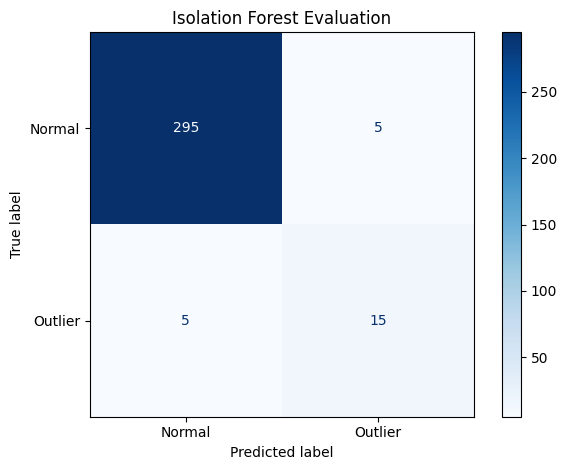

In [11]:
# Construct reference labels:
# 1 = normal, -1 = known synthetic outlier
true_labels = np.concatenate([
    np.ones(len(X), dtype=int),
    -np.ones(len(outliers), dtype=int)
])

predicted_labels = isolation_labels

# Convert labels to binary classes for sklearn metrics:
# 1 = outlier, 0 = normal
y_true_binary = (true_labels == -1).astype(int)
y_pred_binary = (predicted_labels == -1).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true_binary, y_pred_binary))

print("\nClassification Report:")
print(
    classification_report(
        y_true_binary,
        y_pred_binary,
        target_names=["Normal", "Outlier"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_true_binary,
    y_pred_binary,
    display_labels=["Normal", "Outlier"],
    cmap="Blues"
)

plt.title("Isolation Forest Evaluation")
plt.tight_layout()
plt.show()

In [12]:
detection_results = {
    "Isolation Forest": isolation_labels,
    "One-Class SVM": svm_labels,
    "Local Outlier Factor": lof_labels
}

comparison = []

for model_name, labels in detection_results.items():
    predicted_outliers = (labels == -1).astype(int)

    comparison.append({
        "Model": model_name,
        "Precision": classification_report(
            y_true_binary,
            predicted_outliers,
            output_dict=True,
            zero_division=0
        )["1"]["precision"],
        "Recall": classification_report(
            y_true_binary,
            predicted_outliers,
            output_dict=True,
            zero_division=0
        )["1"]["recall"],
        "F1-score": classification_report(
            y_true_binary,
            predicted_outliers,
            output_dict=True,
            zero_division=0
        )["1"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))

,Model,Precision,Recall,F1-score
0,Isolation Forest,0.750,0.75,0.750
1,One-Class SVM,0.455,1.00,0.625
2,Local Outlier Factor,0.800,0.80,0.800


### How It Works

The synthetic dataset contains known normal observations and
artificially generated outliers. These labels make it possible
to compare model predictions with the reference labels.

The confusion matrix shows the number of correct and incorrect
detections. Precision indicates how many detected outliers are
actually outliers, while recall indicates how many known outliers
were detected.

The comparison table evaluates Isolation Forest, One-Class SVM,
and LOF on the same synthetic observations.

These results are specific to this dataset and its parameter settings.
Performance on synthetic data does not guarantee the same performance
on real-world anomaly detection problems.

## 6. Handling Detected Outliers

Detecting an outlier does not automatically mean that it should
be removed from the dataset.

An unusual observation may represent:

- A data entry or measurement error.
- A rare but valid event.
- A change in system behavior.
- A potentially important anomaly.

### Possible Strategies

1. **Investigate:** Examine the observation and its context.
2. **Correct:** Fix the value if a verified data error is found.
3. **Remove:** Exclude an observation only when there is a justified
   reason to do so.
4. **Retain:** Keep unusual but valid observations.
5. **Flag:** Add an indicator so downstream analysis can account
   for the observation.

The appropriate strategy depends on the application and the
consequences of removing valid data.

In [13]:
results_df = pd.DataFrame(
    X_with_outliers,
    columns=["Feature 1", "Feature 2"]
)

results_df["Isolation Forest Label"] = isolation_labels

results_df["Status"] = np.where(
    results_df["Isolation Forest Label"] == -1,
    "Potential Outlier",
    "Inlier"
)

display(results_df.head(10))

print("\nObservations by status:")
display(results_df["Status"].value_counts())

,Feature 1,Feature 2,Isolation Forest Label,Status
0,0.901961,3.724847,1,Inlier
1,1.665560,3.525568,1,Inlier
2,1.457767,4.076025,1,Inlier
3,2.317513,4.056564,1,Inlier
4,0.968949,3.334307,1,Inlier
5,1.505366,3.207989,1,Inlier
6,2.226052,4.286060,1,Inlier
7,2.369820,3.271591,1,Inlier
8,2.818762,3.521457,1,Inlier
9,2.351008,4.173109,1,Inlier



Observations by status:


,count
Status,
Inlier,300
Potential Outlier,20


In [14]:
inlier_data = X_with_outliers[isolation_labels == 1]

summary_before = pd.DataFrame(
    X_with_outliers,
    columns=["Feature 1", "Feature 2"]
).describe()

summary_after = pd.DataFrame(
    inlier_data,
    columns=["Feature 1", "Feature 2"]
).describe()

print("Summary before filtering:")
display(summary_before)

print("\nSummary of observations classified as inliers:")
display(summary_after)

Summary before filtering:


,Feature 1,Feature 2
count,320.000000,320.000000
mean,1.643367,3.721953
std,1.070271,1.422340
min,-5.770717,-5.474297
25%,1.331199,3.444502
50%,1.716440,3.920083
75%,2.189115,4.364057
max,5.530917,6.127855



Summary of observations classified as inliers:


,Feature 1,Feature 2
count,300.000000,300.000000
mean,1.775083,3.956245
std,0.594101,0.635520
min,0.084925,1.983796
25%,1.378351,3.522156
50%,1.760230,3.950431
75%,2.228068,4.369049
max,3.414082,5.541331


### How It Works

The first example adds an anomaly label to each observation rather
than deleting any data.

The second example compares descriptive statistics for all
observations with statistics for observations classified as inliers.

This illustrates how detected outliers can affect summary statistics.
However, the inlier-only summary is not automatically more accurate:
the removed observations may be legitimate and important.

In practical applications, investigate detected anomalies and
document the reason before deciding whether to correct, remove,
retain, or flag them.

## 7. Choosing the Right Detection Technique

Different anomaly detection algorithms have different strengths.

### Isolation Forest

- Uses randomized trees to isolate observations.
- Can be effective on larger datasets.
- Depends on the data structure and parameter choices.

### One-Class SVM

- Learns a boundary around reference observations.
- Can represent nonlinear boundaries with an appropriate kernel.
- Is sensitive to feature scaling and parameter settings.

### Local Outlier Factor

- Compares the local density of observations with their neighbors.
- Can identify observations that are unusual relative to nearby data.
- Requires careful selection of the neighborhood size.

### Selection Considerations

Choose a method based on dataset size, feature characteristics,
the expected type of anomalies, available labels, computational
resources, and the cost of false positives and false negatives.

No single method is best for every anomaly detection problem.

In [15]:
# Adapted exercise: apply Isolation Forest to the synthetic dataset

exercise_if = IsolationForest(
    n_estimators=150,
    contamination=0.06,
    random_state=2024
)

exercise_labels = exercise_if.fit_predict(X_with_outliers)

print("Total observations:", len(X_with_outliers))
print("Detected outliers:", np.sum(exercise_labels == -1))
print("Detected inliers:", np.sum(exercise_labels == 1))

Total observations: 320
Detected outliers: 20
Detected inliers: 300


In [16]:
# Adapted exercise: apply LOF to the synthetic dataset

exercise_lof = LocalOutlierFactor(
    n_neighbors=15,
    contamination=0.06
)

exercise_lof_labels = exercise_lof.fit_predict(X_with_outliers)

print("Detected outliers:", np.sum(exercise_lof_labels == -1))
print("Detected inliers:", np.sum(exercise_lof_labels == 1))

Detected outliers: 20
Detected inliers: 300


In [17]:
# Adapted exercise: fit One-Class SVM on normal reference data

exercise_scaler = StandardScaler()

X_reference = exercise_scaler.fit_transform(X)
X_to_check = exercise_scaler.transform(X_with_outliers)

exercise_svm = OneClassSVM(
    kernel="rbf",
    nu=0.06,
    gamma="scale"
)

exercise_svm.fit(X_reference)

exercise_svm_labels = exercise_svm.predict(X_to_check)

print("Detected novelties:", np.sum(exercise_svm_labels == -1))
print("Detected normal observations:", np.sum(exercise_svm_labels == 1))

Detected novelties: 44
Detected normal observations: 276


In [18]:
exercise_summary = pd.DataFrame({
    "Method": [
        "Isolation Forest",
        "Local Outlier Factor",
        "One-Class SVM"
    ],
    "Detected Outliers": [
        np.sum(exercise_labels == -1),
        np.sum(exercise_lof_labels == -1),
        np.sum(exercise_svm_labels == -1)
    ]
})

display(exercise_summary)

,Method,Detected Outliers
0,Isolation Forest,20
1,Local Outlier Factor,20
2,One-Class SVM,44


## 8. Summary

Chapter 11 introduced techniques for identifying unusual observations
and detecting previously unseen patterns in data.

The main concepts covered were:

1. **Outlier detection:** Identifies observations that deviate from
   the general structure of a dataset.
2. **Novelty detection:** Evaluates new observations against a
   reference dataset representing normal behavior.
3. **Isolation Forest:** Uses randomized trees to isolate unusual
   observations.
4. **One-Class SVM:** Learns a boundary around reference data and
   identifies potential novelties.
5. **Local Outlier Factor:** Compares local observation densities
   to identify potential anomalies.
6. **Evaluation:** Uses precision, recall, F1-score, and confusion
   matrices when reliable reference labels are available.
7. **Handling anomalies:** Requires investigation and domain
   knowledge before correcting, removing, or retaining observations.
8. **Method selection:** Depends on data characteristics, the
   expected anomaly patterns, and the cost of detection errors.

The practical examples demonstrated how to generate data with
outliers, train anomaly detection models, visualize their predictions,
and compare their results.

An anomaly detection model provides a signal for further investigation.
Its predictions should not be treated as definitive proof that an
observation is invalid.

## References

Sukup, J. (2025).
scikit-learn Cookbook, Third Edition.
Packt Publishing.

Official repository:
https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition

## Reproduction Notes

This notebook follows the topics and algorithms covered in Chapter 11.

The initial synthetic outlier example follows the approach described
in the book. Other code cells are organized as runnable demonstrations
and practice exercises. They should not be represented as exact copies
of every recipe in the original book.

For strict code reproduction, compare each section with the original
Chapter 11 recipes in the official repository.